# Validation 4 — Mô phỏng hiệu chỉnh theo dữ liệu thật (20 mã)

1. **H0:** một nhân tố chung với hệ số tải khác nhau, **không có nhân quả giữa các mã** — EASE có tái hiện được ma trận $\hat\Psi$ và thứ tự quan sát?
2. **Độ nhạy (power):** một cạnh $i\to j$ hệ số $b$ chồng lên nhân tố chung được EASE và kiểm định hoán đổi phát hiện với xác suất bao nhiêu?

$$X_t = \lambda F_t + (\sqrt{1-\lambda^2}\odot\varepsilon_t)(I-B)^{-1},\quad F_t, \varepsilon_{i,t}\sim t_\nu \text{ (chuẩn hoá)},$$
$\lambda$: tải một nhân tố (tương quan hạng của $z$), $\nu$: bậc tự do trung bình của GARCH-t, $B$: hệ số giữa các mã ($B = 0$ dưới H0), $F$ ẩn.

## 0. Thiết lập và hiệu chỉnh tham số

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "validation"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

import validation as V
from scipy import stats
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)

Z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")
z = Z[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
E, beta = V.loo_market_adjust(z)                 # phần dư sau khi loại thị trường leave-one-out
print(f"n = {n} phiên ({Z.index[0]:%d/%m/%Y} → {Z.index[-1]:%d/%m/%Y}), {P} mã, k = {K}")

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
gp = pd.read_csv(ROOT / "report" / "table" / "processing" / "02_garch_params.csv", index_col=0, encoding="utf-8-sig")
NU = float(gp["nu"].mean())
lam = V.fit_one_factor(z)
Zs = pd.DataFrame(CB.normal_scores(z), columns=SYMBOLS)
R_fit = np.outer(lam, lam); np.fill_diagonal(R_fit, 1)
print(f"ν = {NU:.2f}; sai lệch tương quan |R_obs − λλᵀ|: TB {np.abs(Zs.corr().values - R_fit)[OFF].mean():.3f}, "
      f"lớn nhất {np.abs(Zs.corr().values - R_fit)[OFF].max():.3f}")
P_obs = CT.tail_coef_matrix(z, k=K); order_obs = CT.ease(P_obs)
rf_obs = pd.read_csv(ROOT / "report" / "table" / "processing" / "02_bootstrap_rank_freq.csv", index_col=0, encoding="utf-8-sig")
rf_obs.columns = rf_obs.columns.astype(int)
lam.sort_values().round(3).to_frame().T

n = 2118 phiên (05/06/2018 → 25/11/2026), 20 mã, k = 21
ν = 3.84; sai lệch tương quan |R_obs − λλᵀ|: TB 0.039, lớn nhất 0.377


,SAB,NVL,VIC,VNM,VHM,GAS,PLX,KDH,MSN,VCB,FPT,HPG,STB,MWG,VPB,BID,TCB,SSI,CTG,MBB
lambda,0.370,0.382,0.413,0.491,0.505,0.520,0.541,0.542,0.569,0.619,0.625,0.657,0.658,0.661,0.704,0.707,0.738,0.745,0.752,0.780


## 1. Dưới H0

**Các bước:** 500 bộ dữ liệu từ H0; mỗi bộ tính $\hat\Psi$ và thứ tự EASE. So sánh (a) $\hat\Psi$ quan sát với dải 90% mô phỏng của 380 cặp;
(b) vị trí trung bình của từng mã dưới H0 và trên dữ liệu thật (bootstrap); (c) tương quan giữa $\hat\Psi$ quan sát và trung bình H0.

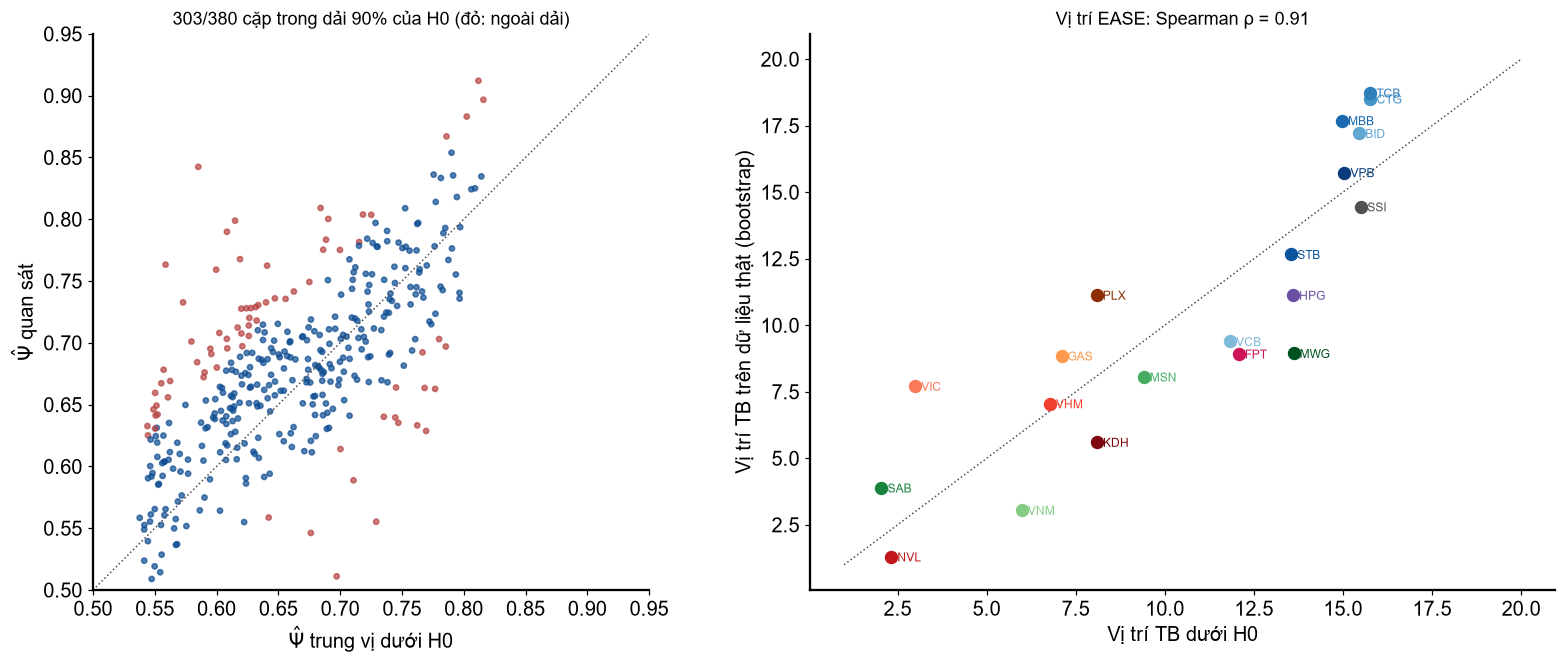

Tương quan Ψ̂ quan sát – trung vị H0: 0.68; P(H0 cho đúng thứ tự đầy đủ) = 0.0%


In [2]:
RSIM = 500
rng = np.random.default_rng(2026)
sims, orders_h0 = [], []
for _ in range(RSIM):
    X = pd.DataFrame(V.simulate_factor_scm(n, lam.values, NU, rng=rng), columns=SYMBOLS)
    M = CT.tail_coef_matrix(X, k=K); sims.append(M.values); orders_h0.append(CT.ease(M))
sims = np.array(sims)
rf_h0 = V.order_frequency(orders_h0, SYMBOLS)
lo, hi, mid = (np.nanquantile(sims, q, axis=0) for q in (0.05, 0.95, 0.5))
obs = P_obs.values
inside = ((obs >= lo) & (obs <= hi))[OFF]
pos_h0 = (rf_h0 * np.arange(1, P + 1)).sum(axis=1); pos_obs = (rf_obs.loc[SYMBOLS] * np.arange(1, P + 1)).sum(axis=1)
U.save_table(pd.DataFrame({"cap": [f"{a}→{b}" for a in SYMBOLS for b in SYMBOLS if a != b], "psi_obs": obs[OFF],
                           "h0_q05": lo[OFF], "h0_median": mid[OFF], "h0_q95": hi[OFF]}).set_index("cap"),
             "04_h0_psi_band", FOLDER)
U.save_table(pd.DataFrame({"vi_tri_TB_H0": pos_h0, "vi_tri_TB_that": pos_obs, "goc_H0": rf_h0[1], "goc_that": rf_obs.loc[SYMBOLS, 1]}),
             "04_h0_vs_observed", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
ax = axes[0]
ax.scatter(mid[OFF], obs[OFF], s=12, alpha=0.7, color=np.where(inside, PAL["blue_main"], PAL["red_strong"]))
lim = [0.5, 0.95]; ax.plot(lim, lim, color=PAL["gray_dark"], ls=":", lw=1); ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel(r"$\hat\Psi$ trung vị dưới H0"); ax.set_ylabel(r"$\hat\Psi$ quan sát")
ax.set_title(f"{inside.sum()}/380 cặp trong dải 90% của H0 (đỏ: ngoài dải)", fontsize=12)
ax = axes[1]
for s in SYMBOLS:
    ax.scatter(pos_h0[s], pos_obs[s], s=60, color=COL[s], zorder=3)
    ax.annotate(s, (pos_h0[s], pos_obs[s]), xytext=(4, -3), textcoords="offset points", fontsize=8, color=COL[s])
ax.plot([1, P], [1, P], color=PAL["gray_dark"], ls=":", lw=1)
ax.set_xlabel("Vị trí TB dưới H0"); ax.set_ylabel("Vị trí TB trên dữ liệu thật (bootstrap)")
rho_pos = stats.spearmanr(pos_h0, pos_obs)[0]
ax.set_title(f"Vị trí EASE: Spearman ρ = {rho_pos:.2f}", fontsize=12)
U.finalize_figure(fig, "04_h0_comparison", folder=FOLDER); plt.show()
print(f"Tương quan Ψ̂ quan sát – trung vị H0: {np.corrcoef(obs[OFF], mid[OFF])[0, 1]:.2f}; "
      f"P(H0 cho đúng thứ tự đầy đủ) = {np.mean([o == order_obs for o in orders_h0]):.1%}")

In [3]:
# Các cặp nằm ngoài dải 90% (phụ thuộc đuôi mà mô hình một nhân tố KHÔNG giải thích được)
band = pd.read_csv(ROOT / "report" / "table" / "validation" / "04_h0_psi_band.csv", index_col=0, encoding="utf-8-sig")
out = band[(band.psi_obs > band.h0_q95) | (band.psi_obs < band.h0_q05)].assign(
    chenh=lambda d: d.psi_obs - d.h0_median).sort_values("chenh", ascending=False)
print(f"{len(out)} cặp ngoài dải; vượt trên: {(out.chenh > 0).sum()}, dưới: {(out.chenh < 0).sum()}")
out.head(15).round(3)

77 cặp ngoài dải; vượt trên: 59, dưới: 18


,psi_obs,h0_q05,h0_median,h0_q95,chenh
cap,,,,,
VHM→VIC,0.842,0.497,0.585,0.659,0.257
VIC→VHM,0.763,0.477,0.559,0.634,0.205
PLX→GAS,0.799,0.528,0.615,0.697,0.184
GAS→PLX,0.790,0.524,0.608,0.681,0.182
VNM→SAB,0.733,0.489,0.573,0.643,0.160
GAS→VHM,0.759,0.517,0.600,0.679,0.160
GAS→HPG,0.768,0.541,0.619,0.692,0.149
VCB→BID,0.809,0.596,0.684,0.757,0.125
PLX→CTG,0.762,0.563,0.641,0.714,0.122


### Phân tích


- Tải một nhân tố $\hat\lambda$ từ 0,37 (SAB) đến 0,78 (MBB); sai lệch tương quan trung bình 0,04 nhưng lớn nhất 0,38 (cặp cùng tập đoàn/ngành).
- **Vị trí EASE dưới H0 tương quan ρ = 0,91 với vị trí thật** — một mô hình **không có nhân quả giữa các mã** tái hiện gần đúng toàn bộ thứ tự.
- Nhưng H0 **không** giải thích hết ma trận: 77/380 cặp nằm ngoài dải 90% (kỳ vọng ~38), 59 vượt trên. Các cặp vượt nhiều nhất đều **cùng ngành/tập đoàn**:
  VHM↔VIC (+0,26/+0,21), PLX↔GAS (+0,18), VNM→SAB (+0,16), VCB→BID (+0,13), MWG→MSN (+0,11), NVL→KDH (+0,11). Đây là phụ thuộc đuôi ngành mà một nhân tố không có.
- Gốc dưới H0 thường là SAB (43%) hoặc NVL (34%); trên dữ liệu thật NVL áp đảo (82%) — NVL có nhiều cú sốc riêng hơn mức mô hình $t_\nu$ mô tả.

## 2. Độ nhạy: EASE phát hiện được cạnh nhân quả cỡ nào?

Thêm một cạnh $i \to j$ hệ số $b \in \{0;\,0{,}1;\,0{,}2;\,0{,}3;\,0{,}5\}$ vào mô hình đã hiệu chỉnh cho hai cạnh đại diện: **mã tải cao → mã tải thấp**
(MBB → SAB) và **hai mã tải gần nhau** (CTG → BID). 100 lần lặp mỗi $(b,$ cạnh$)$; đo tỷ lệ EASE đặt nguyên nhân trước hệ quả và tỷ lệ kiểm định
hoán đổi ($B = 199$) bác bỏ đúng chiều ở 5%. Chạy song song theo lần lặp (joblib).

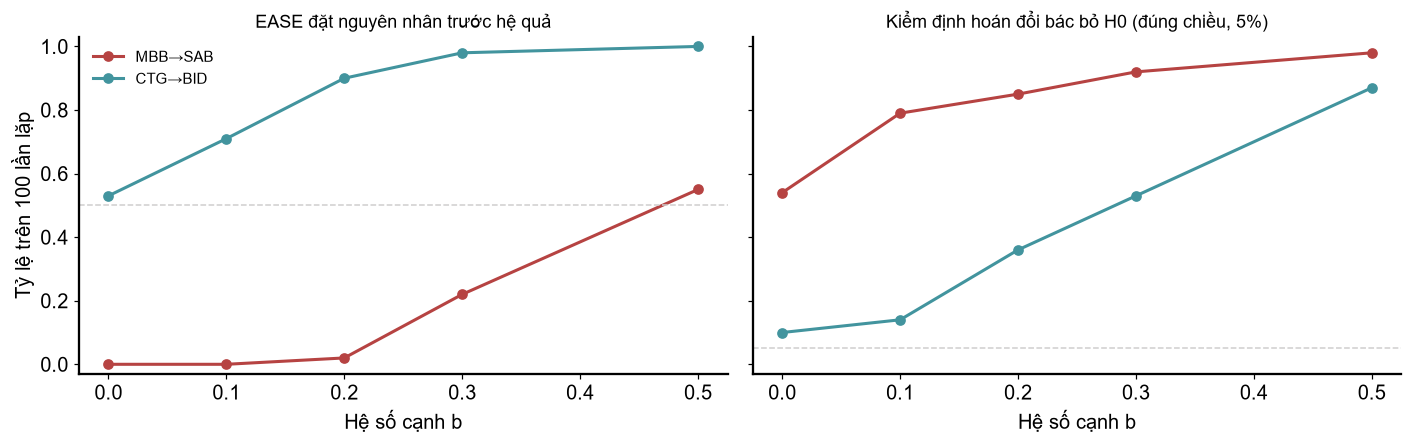

ease_dung_chieu         swap_bac_bo_dung_chieu        
canh          CTG→BID MBB→SAB                CTG→BID MBB→SAB
b                                                           
0.000           0.530   0.000                  0.100   0.540
0.100           0.710   0.000                  0.140   0.790
0.200           0.900   0.020                  0.360   0.850
0.300           0.980   0.220                  0.530   0.920
0.500           1.000   0.550                  0.870   0.980

In [4]:
from joblib import Parallel, delayed
EDGES = [("MBB", "SAB"), ("CTG", "BID")]
BS = [0.0, 0.1, 0.2, 0.3, 0.5]
REP, BSW = 100, 199

def one(c, e, b, child):
    ic, ie = SYMBOLS.index(c), SYMBOLS.index(e)
    rng_ = np.random.default_rng(child)
    Bc = np.zeros((P, P)); Bc[ic, ie] = b
    X = V.simulate_factor_scm(n, lam.values, NU, B_coef=Bc, rng=rng_)
    o = CT.ease(CT.tail_coef_matrix(X, k=K))
    d, null = V.swap_null_asymmetry(X[:, ic], X[:, ie], k=K, B=BSW, seed=int(rng_.integers(1 << 30)))
    return {"canh": f"{c}→{e}", "b": b, "ease_dung_chieu": o.index(ic) < o.index(ie),
            "swap_bac_bo_dung_chieu": (V.perm_pvalue(d, null) < 0.05) and d > 0}

tasks = [(c, e, b) for (c, e) in EDGES for b in BS for _ in range(REP)]
children = np.random.SeedSequence(7).spawn(len(tasks))
rows = Parallel(n_jobs=-1)(delayed(one)(*t, ch) for t, ch in zip(tasks, children))
power = pd.DataFrame(rows).groupby(["canh", "b"]).mean()
U.save_table(power, "04_power", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (col, title) in zip(axes, [("ease_dung_chieu", "EASE đặt nguyên nhân trước hệ quả"),
                                   ("swap_bac_bo_dung_chieu", "Kiểm định hoán đổi bác bỏ H0 (đúng chiều, 5%)")]):
    for edge, colr in zip([f"{c}→{e}" for c, e in EDGES], [PAL["red_strong"], PAL["teal"]]):
        g = power.loc[edge, col]
        ax.plot(g.index, g.values, "o-", color=colr, lw=2, ms=6, label=edge)
    ax.set_xlabel("Hệ số cạnh b"); ax.set_title(title, fontsize=12); ax.set_ylim(-0.03, 1.03)
    ax.axhline(0.05 if "swap" in col else 0.5, color=PAL["neutral"], ls="--", lw=1)
axes[0].set_ylabel("Tỷ lệ trên 100 lần lặp"); axes[0].legend(fontsize=10)
U.finalize_figure(fig, "04_power", folder=FOLDER); plt.show()
power.unstack(0).round(2)

### Phân tích


- **Cạnh giữa hai mã tải gần nhau (CTG → BID):** ở $b = 0$ EASE đặt CTG trước BID 53% (tung đồng xu); phát hiện tin cậy từ $b \approx 0{,}2$ (90%) và $b = 0{,}3$ (98%).
  Kiểm định hoán đổi: sai loại I 10% ở $b = 0$ (gấp đôi danh nghĩa), power 0,53 ở $b = 0{,}3$, 0,87 ở $b = 0{,}5$.
- **Cạnh từ mã tải cao sang mã tải thấp (MBB → SAB):** EASE gần như **không thể** phát hiện — ở $b = 0$ luôn đặt SAB trước MBB (0%), $b = 0{,}5$ mới đạt 55%.
  Kiểm định hoán đổi bác bỏ sai **54%** khi không có cạnh nào: chênh lệch hệ số tải tự tạo ra bất đối xứng.
- Hệ quả: với dữ liệu 20 mã, mọi kết luận về chiều giữa hai mã có **hệ số tải khác nhau** đều phải hiệu chỉnh bằng mô phỏng; p-value thô của kiểm định hoán đổi không dùng được.

## 3. Kết luận


1. Mô hình một nhân tố không có nhân quả giữa các mã tái hiện **thứ tự** EASE (ρ = 0,91) nhưng **không** tái hiện hết các hệ số: còn phụ thuộc đuôi theo ngành/tập đoàn.
2. EASE chỉ phát hiện được cạnh trực tiếp khi hệ số ≥ 0,2–0,3 **và** hai mã có tải tương đương; cạnh từ mã tải cao sang mã tải thấp gần như vô hình.
3. Kiểm định hoán đổi có sai loại I tới 54% khi tải lệch nhiều — chỉ dùng kèm hiệu chỉnh bằng mô phỏng.